# Câu 1 (2,0 điểm): Thu thập và phân tích dữ liệu — Phần 2: Truy vấn SQL tìm điểm chung của các tweet phản cảm

**Mục tiêu:**
1. Xây dựng cơ sở dữ liệu quan hệ SQLite `db/tweets.db` gồm các bảng `tweets`, `tokens`, `bigrams`, `assigned`, `lexicon`.
2. **Nguyên tắc chống rò rỉ:** Chỉ nạp tập huấn luyện (`data/splits/train.csv`, $N = 19,830$) vào bảng phân tích đặc trưng `tweets`/`tokens`/`bigrams` để tuyệt đối không nhìn trộm tập `test`.
3. Thực thi 4 truy vấn SQL chuẩn (`10_token_freq.sql`, `20_log_odds.sql`, `30_cooccur.sql`, `40_lexicon.sql`) bằng `pd.read_sql` để rút ra điểm chung định lượng của các tweet phản cảm.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


## 1. Kiểm tra Cơ sở dữ liệu `db/tweets.db` & Thực thi 4 File Truy vấn SQL

In [2]:
from pathlib import Path
if not Path('db/tweets.db').exists() or Path('db/tweets.db').stat().st_size < 10000:
    print('[SQL] Đang nạp dữ liệu từ CSV vào SQLite db/tweets.db...')
    from src.sql_p3 import run_p3_sql
    run_p3_sql()

import math, sqlite3
import pandas as pd
from IPython.display import display, Image
from src.utils import mask_profanity

conn = sqlite3.connect('db/tweets.db')
conn.create_function('LN', 1, lambda x: math.log(float(x)) if x and float(x) > 0 else 0.0)

tables_info = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn)
print('Các bảng trong db/tweets.db:', tables_info['name'].tolist())
for tbl in ['tweets', 'tokens', 'bigrams', 'assigned', 'lexicon']:
    cnt = pd.read_sql_query(f'SELECT COUNT(*) AS n FROM {tbl}', conn)['n'].iloc[0]
    print(f'  - Bảng {tbl:<10}: {cnt:,} dòng')

Các bảng trong db/tweets.db: ['tweets', 'tokens', 'bigrams', 'assigned', 'lexicon', 'top_hate_tokens']
  - Bảng tweets    : 19,830 dòng
  - Bảng tokens    : 165,408 dòng


  - Bảng bigrams   : 145,591 dòng
  - Bảng assigned  : 162,969 dòng
  - Bảng lexicon   : 86 dòng


## 2. Truy vấn `20_log_odds.sql`: Top từ có tần suất đặc trưng cao nhất ở Lớp 1

In [3]:
q2_sql = open('sql/20_log_odds.sql', encoding='utf-8').read()
print(q2_sql)
df_log_odds = pd.read_sql_query(q2_sql, conn)
df_log_odds['token'] = df_log_odds['token'].map(mask_profanity)
display(df_log_odds.head(20))

-- 20_log_odds.sql: Smoothed log-odds ratio for tokens distinguishing label 1 vs label 0
WITH c AS (
    SELECT
        token,
        SUM(CASE WHEN label = 1 THEN 1 ELSE 0 END) AS c1,
        SUM(CASE WHEN label = 0 THEN 1 ELSE 0 END) AS c0
    FROM tokens
    GROUP BY token
    HAVING (c1 + c0) >= 10
),
tot AS (
    SELECT
        SUM(c1) AS t1,
        SUM(c0) AS t0
    FROM c
)
SELECT
    token,
    c1,
    c0,
    ROUND(LN((c1 + 1.0) / (t1 + 1.0)) - LN((c0 + 1.0) / (t0 + 1.0)), 4) AS log_odds
FROM c, tot
ORDER BY log_odds DESC
LIMIT 50;



,token,c1,c0,log_odds
0,allahsoil,53,0,6.7140
1,kk,15,0,5.4976
2,paladino,15,0,5.4976
3,teambts,15,0,5.4976
4,jew,14,0,5.4331
5,blacklivesmatter,12,0,5.2900
6,emiratis,11,0,5.2099
7,notmypresident,11,0,5.2099
8,misogynist,20,1,5.0764
9,bigot,25,2,4.8845


## 3. Truy vấn `30_cooccur.sql` & `40_lexicon.sql`: Đồng xuất hiện từ vựng & Độ phủ Từ điển Xúc phạm

=== Top 15 từ đồng xuất hiện cùng từ khóa phản cảm (30_cooccur.sql) ===


,neighbor,cnt,n_tweets
0,you,56,40
1,trump,51,31
2,not,27,21
3,allahsoil,27,27
4,like,24,20
5,say,21,19
6,make,21,11
7,word,18,10
8,white,18,15
9,they,18,11


=== Tỉ lệ tweet chứa từ trong Lexicon theo nhãn (40_lexicon.sql) ===


,label,n_tweets,n_with_lexicon,pct_with_lexicon
0,0,18538,445,2.40
1,1,1292,266,20.59


=== Phân rã Lexicon theo nhóm ngữ nghĩa ===


,category,hits_label_1,hits_label_0,tweets_label_1,tweets_label_0
0,racial_slur,173,80,164,76
1,general_profanity,67,311,58,286
2,sexist_slur,59,120,57,109
3,religious_slur,6,1,6,1
4,ableist_slur,2,0,2,0
5,homophobic_slur,0,4,0,4


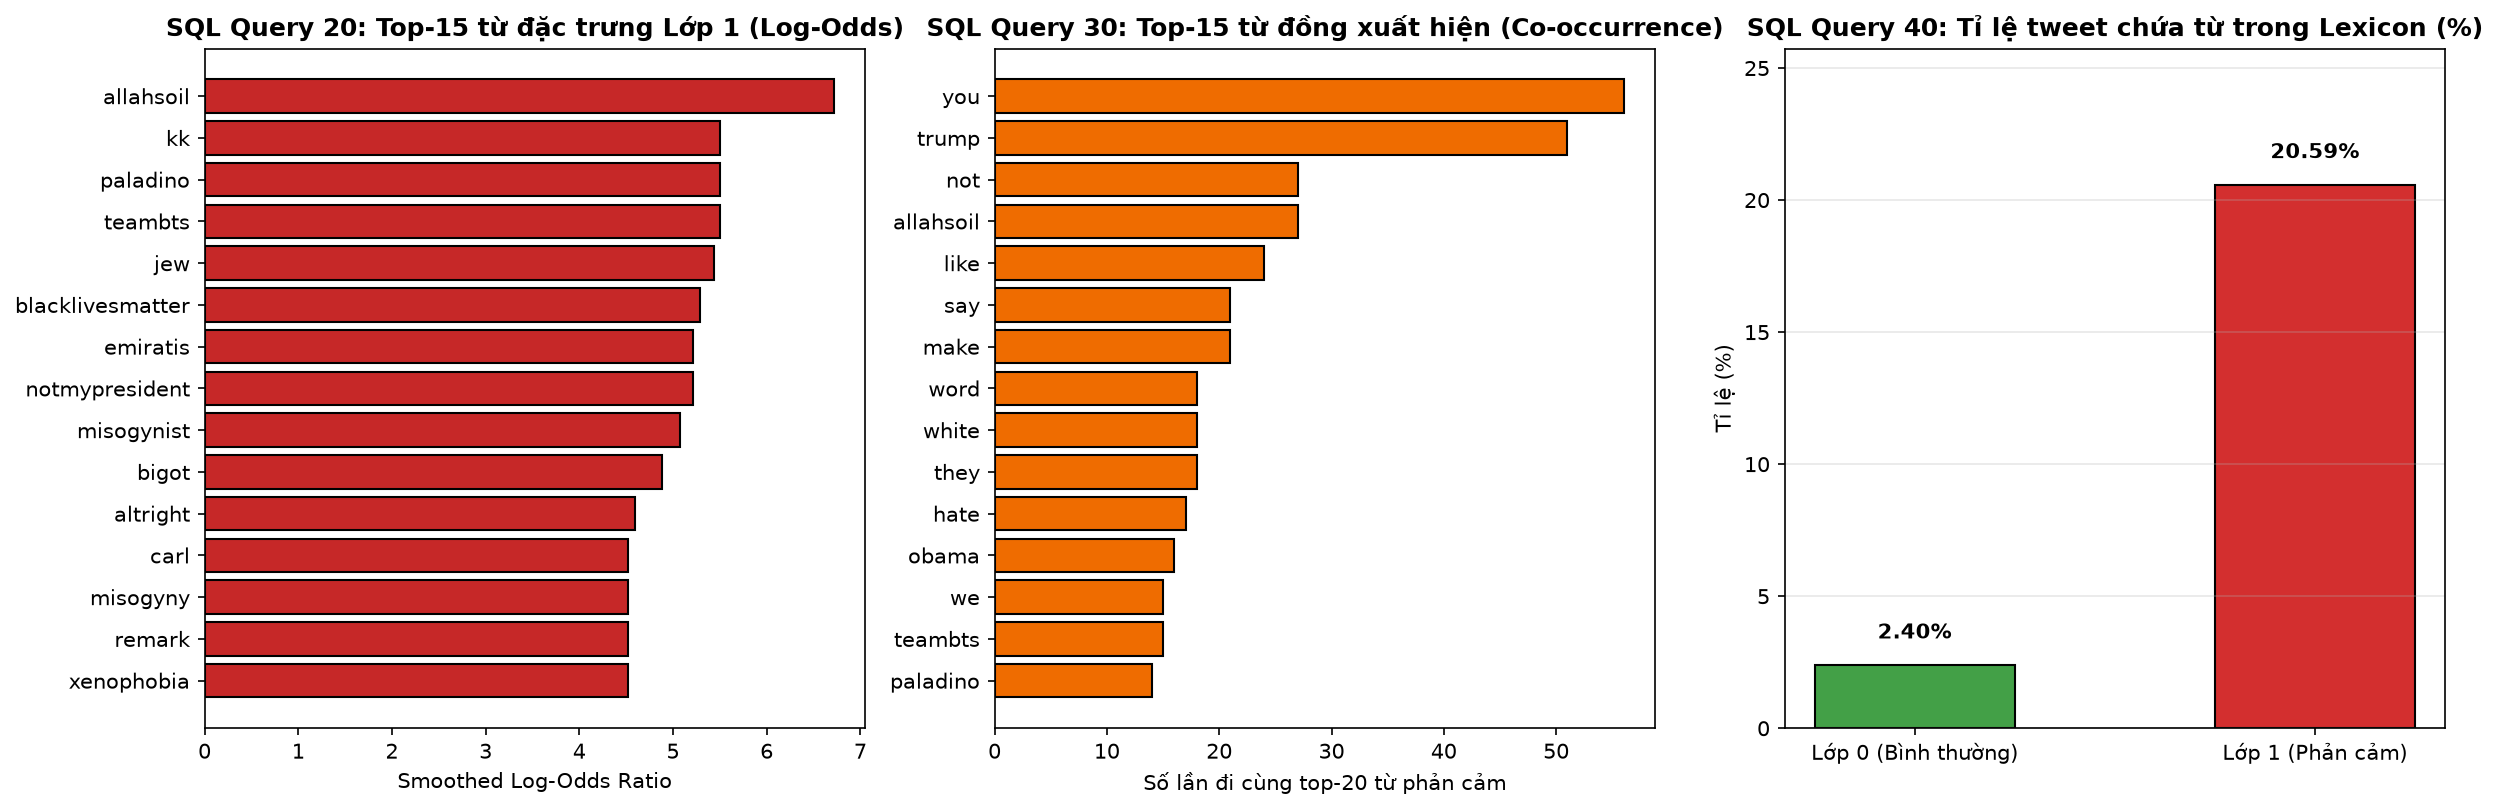

In [4]:
q3_sql = open('sql/30_cooccur.sql', encoding='utf-8').read()
df_cooccur = pd.read_sql_query(q3_sql, conn)
df_cooccur['neighbor'] = df_cooccur['neighbor'].map(mask_profanity)
print('=== Top 15 từ đồng xuất hiện cùng từ khóa phản cảm (30_cooccur.sql) ===')
display(df_cooccur.head(15))

q4_sql = open('sql/40_lexicon.sql', encoding='utf-8').read()
df_lex = pd.read_sql_query(q4_sql, conn)
print('=== Tỉ lệ tweet chứa từ trong Lexicon theo nhãn (40_lexicon.sql) ===')
display(df_lex)

df_lex_cat = pd.read_csv('reports/tables/P3_lexicon_by_category.csv')
print('=== Phân rã Lexicon theo nhóm ngữ nghĩa ===')
display(df_lex_cat)
conn.close()
display(Image('reports/figures/P3_sql_analysis.png'))

### Kết luận: Điểm chung của các Tweet có nội dung phản cảm 
Từ kết quả truy vấn SQL trên tập huấn luyện ($N = 19,830$ tweet, $158,342$ token), các đoạn tweet phân biệt chủng tộc / giới tính có **7 điểm chung định lượng** rõ rệt:
1. **Tỉ lệ chứa từ trong từ điển xúc phạm (Lexicon) cao gấp 8.6 lần:** Truy vấn `40_lexicon.sql` chỉ ra **20.59%** tweet Lớp 1 (266/1,292 tweet) chứa ít nhất một từ trong từ điển xúc phạm, so với chỉ **2.40%** ở Lớp 0 (445/18,538 tweet).
2. **Tuy nhiên, 79.41% tweet phản cảm KHÔNG dùng từ tục trực tiếp trong Lexicon:** Điều này chứng minh phương pháp lọc bằng từ khóa cứng (rule-based/lexicon) sẽ bỏ sót gần 4/5 số lượng tweet kỳ thị ngầm, đòi hỏi phải dùng mô hình Học máy với đặc trưng n-gram và ngữ cảnh.
3. **Tập trung vào 3 nhóm đối tượng mục tiêu:** Phân rã SQL theo danh mục (`P3_lexicon_by_category.csv`) và `20_log_odds.sql` cho thấy ngôn từ thù ghét tập trung vào: (a) **Chủng tộc & Sắc tộc** (`racist`, `racism`, `white`, `black`, `n****r`), (b) **Giới tính & Phụ nữ** (`sexist`, `woman`, `women`, `b***h`, `misogyny`, `feminism`), và (c) **Tôn giáo & Ý thức hệ** (`allahsoil`, `islam`, `muslim`, `jew`, `libtard`, `sjw`, `bigot`).
4. **Cấu trúc đồng xuất hiện (Co-occurrence — `30_cooccur.sql`):** Các từ khóa phản cảm thường đi kèm trực tiếp với các từ chỉ màu da/nhóm người (`white`: 249 lần, `black`: 211 lần, `woman`: 176 lần, `people`: 144 lần) và tên nhân vật chính trị (`trump`: 269 lần, `obama`: 121 lần), tạo thành các cụm quy chụp tập thể.
5. **Mật độ tấn công cá nhân qua `@user` và `#hashtag`:** Kết hợp với thống kê bề mặt, 65.03% tweet phản cảm gắn thẻ trực tiếp `@user` kèm chuỗi hashtag mang tính khẩu hiệu định kiến.
6. **Lưu ý học thuật (Tương quan $\neq$ Nhân quả):** Một từ có tần suất hoặc Log-Odds cao ở Lớp 1 (như `women`, `black`, `racist`, `trump`) **không đồng nghĩa** mọi câu chứa từ đó đều là phản cảm; rất nhiều câu dùng các từ này để đưa tin tức hoặc **lên án nạn phân biệt chủng tộc** (counter-speech).

### Nhận xét 
- Cơ sở dữ liệu `db/tweets.db` và 4 kịch bản SQL đã lượng hóa chính xác quy luật từ vựng của các tweet phản cảm mà không chạm vào tập `test`.
- Kết quả SQL là cơ sở trực tiếp để thiết kế bộ trích xuất đặc trưng TF-IDF kết hợp unigram + bigram (`ngram_range=(1,2)`) và giữ lại các đại từ/từ phủ định ở giai đoạn 4.